# 05 · Semi-synthetic experiment and real case studies (RQ1, RQ4)

**Part 1 — semi-synthetic label shuffling.** Real feature matrices, known ordering of signal strength. For each base dataset, the labels of a random fraction *q* of rows are shuffled among themselves. This keeps the feature distribution and class balance exactly, while signal shrinks as *q* grows; at *q* = 1 the labels are a full permutation, so H₀ holds exactly.

Because the feature matrix of a base dataset never changes, the permutation null distribution of every probe is computed **once per base dataset** (it depends only on X and the class counts) and shared by all its replicates. Each p-value is therefore an exact permutation p-value.

| Base dataset | Rows used | Note |
|---|---|---|
| Adult | 2,000 (fixed stratified subsample) | the required signal dataset |
| Pima Indians Diabetes | 768 | moderate signal |
| Breast Cancer Wisconsin | 569 | strong signal |
| Banknote Authentication | 1,372 | very strong, mostly non-linear signal |

q ∈ {0, 0.25, 0.5, 0.75, 0.9, 1.0}; 10 replicates per q; permutations B = 200 (model-free probes, M1, M2) and B = 100 (M3, M4).

**Part 2 — case studies.** The full protocol (sanity check → all probes with permutation tests → effect sizes) on **Adult** (signal), on two datasets with no signal by design (the **NSW randomised experiment** and the **Malawi randomised incentive experiment** with individual covariates), and on the incentive experiment **including village**, where assignment rates varied by village.

In [1]:
import json
import zlib
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True
exec(compile(load_library_source(), "probe_library", "exec"))
import matplotlib.pyplot as plt

Q_GRID = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]
REPS = 10
B_CHEAP, B_HEAVY = 200, 100
HEAVY = {"M3_Forest", "M4_HGB"}

## Part 1 · Semi-synthetic label shuffling

In [2]:
rng = np.random.default_rng(GLOBAL_SEED + 5)
bases = {
    "adult": subsample(from_dataframe(load_processed("adult"), "adult"), 2000, rng),
    "pima": from_dataframe(load_processed("pima"), "pima"),
    "breast_cancer": from_dataframe(load_processed("breast_cancer"), "breast_cancer"),
    "banknote": from_dataframe(load_processed("banknote"), "banknote"),
}

def shuffle_fraction(y, q, rng):
    """Shuffle the labels of a random fraction q of rows among themselves (class counts unchanged)."""
    y = y.copy()
    k = int(round(q * len(y)))
    idx = rng.choice(len(y), size=k, replace=False)
    y[idx] = y[rng.permutation(idx)]
    return y


def base_job(name, probe):
    """Permutation null of one probe on one base dataset, plus the statistic for every (q, replicate)."""
    data = bases[name]
    B = B_HEAVY if probe.name in HEAVY else B_CHEAP
    prng = np.random.default_rng(zlib.crc32(f"{name}|{probe.name}".encode()))   # deterministic seed
    if getattr(probe, "parametric", False):            # S2: analytic p-values, no null needed
        st, null = None, None
    else:
        st = probe.prepare(data)
        null = np.array([probe.stat(st, prng.permutation(data.y)) for _ in range(B)])
    rows = []
    for q in Q_GRID:
        for r in range(REPS):
            yq = shuffle_fraction(data.y, q, np.random.default_rng(1000 * r + int(100 * q)))
            if getattr(probe, "parametric", False):
                pv = probe.pvalues(data, yq)
                p, stat_val = simes(pv), -np.log10(max(simes(pv), 1e-300))
            elif probe.per_feature:
                t = np.asarray(probe.stat(st, yq))
                pv = (1 + (null >= t - 1e-12).sum(0)) / (B + 1)
                p, stat_val = simes(pv), float(t.max())
            else:
                stat_val = float(probe.stat(st, yq))
                p = mc_pvalue(stat_val, null)
            rows.append({"dataset": name, "probe": probe.name, "q": q, "rep": r,
                         "statistic": stat_val, "p": p, "B": B})
    return rows

cache = os.path.join(RESULTS_DIR, "semisynthetic.csv")
if os.path.exists(cache):
    semi = pd.read_csv(cache)
else:
    t0 = time.time()
    jobs = [(name, pr) for name in bases for pr in all_probes()]
    semi = pd.DataFrame([r for rows in Parallel(n_jobs=2)(delayed(base_job)(*j) for j in jobs) for r in rows])
    semi.to_csv(cache, index=False)
    print(f"semi-synthetic runtime: {(time.time()-t0)/60:.1f} min")
semi["reject"] = semi.p <= ALPHA
print(semi.shape)

(2640, 8)


### Detection rate against the shuffled fraction q

At q = 1 the detection rate is the false-positive rate; at smaller q it is power.

In [3]:
det = semi.groupby(["dataset", "probe", "q"]).reject.mean().reset_index()
det.to_csv(os.path.join(RESULTS_DIR, "semisynthetic_detection.csv"), index=False)
det.pivot_table(index=["dataset", "q"], columns="probe", values="reject")[PROBE_ORDER].round(2)

probe               S1_MI  S2_ANOVA_Chi2  S3_dCor  ...  M2_LogReg  M3_Forest  M4_HGB
dataset       q                                    ...                              
adult         0.00    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.25    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.50    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.75    1.0            1.0      1.0  ...        1.0        1.0     0.7
              0.90    0.1            0.2      0.6  ...        0.1        0.3     0.0
              1.00    0.0            0.0      0.0  ...        0.0        0.0     0.1
banknote      0.00    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.25    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.50    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.75    0.3            1.0      1.0  ...        1.0        1.0     1.0
              0.90    0.1            0.7      0.7  ...        0.7        0.2     0.1
              1.00    0.0            0.0      0.0  ...        0.0        0.0     0.1
breast_cancer 0.00    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.25    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.50    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.75    0.1            1.0      1.0  ...        0.9        0.9     0.8
              0.90    0.0            0.6      0.8  ...        0.2        0.3     0.3
              1.00    0.0            0.0      0.0  ...        0.0        0.1     0.1
pima          0.00    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.25    1.0            1.0      1.0  ...        1.0        1.0     1.0
              0.50    0.6            1.0      1.0  ...        1.0        1.0     0.9
              0.75    0.1            0.9      0.9  ...        0.7        0.5     0.1
              0.90    0.2            0.2      0.4  ...        0.2        0.0     0.1
              1.00    0.1            0.1      0.0  ...        0.2        0.0     0.2

[24 rows x 11 columns]

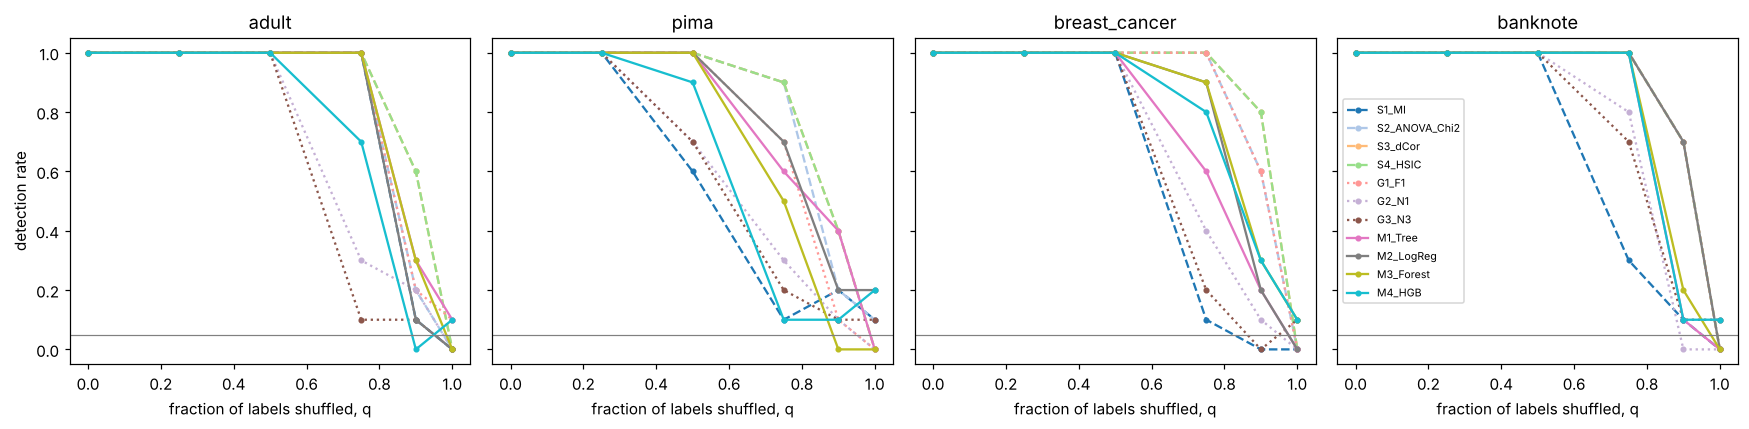

In [4]:
colors = plt.cm.tab20(np.linspace(0, 1, 12))
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, bases):
    for k, probe in enumerate(PROBE_ORDER):
        g = det[(det.dataset == name) & (det.probe == probe)]
        ls = "-" if FAMILY[probe] == "model-based" else ("--" if FAMILY[probe] == "statistical" else ":")
        ax.plot(g.q, g.reject, ls, marker="o", ms=3, color=colors[k], label=probe)
    ax.axhline(ALPHA, color="grey", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("fraction of labels shuffled, q")
axes[0].set_ylabel("detection rate")
axes[-1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "semisynthetic_detection.png"), dpi=200, bbox_inches="tight")
plt.show()

### Agreement of probe statistics with true signal strength (H4a)

Spearman correlation between each probe's statistic and the retained signal fraction 1 − q, per base dataset (60 values each).

In [5]:
agree = (semi.assign(strength=1 - semi.q)
             .groupby(["dataset", "probe"])
             .apply(lambda g: stats.spearmanr(g.statistic, g.strength).statistic, include_groups=False)
             .rename("spearman_rho").reset_index())
agree.to_csv(os.path.join(RESULTS_DIR, "semisynthetic_spearman.csv"), index=False)
agree.pivot(index="probe", columns="dataset", values="spearman_rho").loc[PROBE_ORDER].round(3)

dataset,adult,banknote,breast_cancer,pima
probe,,,,
S1_MI,0.895,0.922,0.904,0.871
S2_ANOVA_Chi2,0.978,0.988,0.986,0.960
S3_dCor,0.980,0.987,0.988,0.973
S4_HSIC,0.977,0.986,0.988,0.973
G1_F1,0.973,0.988,0.984,0.970
G2_N1,0.936,0.961,0.940,0.902
G3_N3,0.892,0.946,0.918,0.869
M1_Tree,0.966,0.979,0.942,0.940
M2_LogReg,0.962,0.982,0.978,0.950


## Part 2 · Case studies

### 2.1 Sanity check on both datasets

In [6]:
adult_df, nsw_df, th_df = load_processed("adult"), load_processed("nsw_null"), load_processed("thornton_null")
th_v_df = load_processed("thornton_village")
CASES = [("Adult", adult_df), ("NSW (randomised)", nsw_df), ("Thornton (randomised)", th_df),
         ("Thornton incl. village", th_v_df)]
sc = pd.DataFrame({name: sanity_check(df) for name, df in CASES}).T
sc

,id_like_columns,exact_duplicates,duplicate_rate,max_single_feature_auc,best_single_feature,flagged_features,verdict
Adult,[],52,0.001065,0.777963,relationship,[],clean
NSW (randomised),[],73,0.164045,0.563254,nodegree,[],clean
Thornton (randomised),[],45,0.015512,0.522695,age,[],clean
Thornton incl. village,[],45,0.015512,0.658749,villnum,[],clean


### 2.2 All probes with permutation tests

Probes whose cost grows with n² run on a stratified 5,000-row subsample of Adult; model-based probes run on a 10,000-row subsample for the permutation test (compute budget). S2 uses all rows. NSW (445 rows) is used in full with B = 1,000 permutations and Thornton (2,901 rows) with B = 500; M3 and M4 use B = 200 on both.

In [7]:
def case_job(name, df, probe, B):
    data = from_dataframe(df, name)
    r = run_probe(probe, data, B=B, seed=2026)
    r["dataset"] = name
    return r

cache = os.path.join(RESULTS_DIR, "case_studies_probes.csv")
if os.path.exists(cache):
    cases = pd.read_csv(cache)
else:
    jobs = []
    for name, df, b_cheap, b_heavy in [("Adult", adult_df, 200, 40), ("NSW (randomised)", nsw_df, 1000, 200),
                                       ("Thornton (randomised)", th_df, 500, 200),
                                       ("Thornton incl. village", th_v_df, 500, 200)]:
        for pr in all_probes():
            jobs.append((name, df, pr, b_heavy if pr.name in HEAVY else b_cheap))
    cases = pd.DataFrame(Parallel(n_jobs=2)(delayed(case_job)(*j) for j in jobs))
    cases.to_csv(cache, index=False)
cases["verdict"] = np.where(cases.p <= ALPHA, "signal detected", "no signal detected")
cases[["dataset", "probe", "statistic", "p", "B_done", "n_used", "verdict", "seconds_total"]].round(4)

,dataset,probe,statistic,p,B_done,n_used,verdict,seconds_total
0,Adult,S1_MI,0.1155,0.0054,200,5000,signal detected,26.0955
1,Adult,S2_ANOVA_Chi2,300.0000,0.0000,0,48842,signal detected,0.1226
2,Adult,S3_dCor,0.4002,0.0050,200,5000,signal detected,6.7252
3,Adult,S4_HSIC,0.0049,0.0050,200,5000,signal detected,6.5383
4,Adult,G1_F1,0.3320,0.0050,200,5000,signal detected,0.8909
5,Adult,G2_N1,-0.3036,0.0050,200,5000,signal detected,9.4547
6,Adult,G3_N3,-0.2060,0.0050,200,5000,signal detected,0.2606
7,Adult,M1_Tree,0.8487,0.0050,200,10000,signal detected,29.1017
8,Adult,M2_LogReg,0.9028,0.0050,200,10000,signal detected,113.2955
9,Adult,M3_Forest,0.9101,0.0244,40,10000,signal detected,110.0005


### 2.3 Effect sizes on the full data (repeated 5-fold CV, 5 repeats)

In [8]:
cache = os.path.join(RESULTS_DIR, "case_studies_gains.csv")
if os.path.exists(cache):
    gains = pd.read_csv(cache)
else:
    rows = []
    for name, df in CASES:
        data = from_dataframe(df, name)
        for key, label in [("tree", "M1_Tree"), ("logreg", "M2_LogReg"), ("forest", "M3_Forest"), ("hgb", "M4_HGB")]:
            t0 = time.time()
            g = repeated_cv_gain(key, data, repeats=5, seed=11)
            rows.append({"dataset": name, "probe": label, "n": data.n, **g, "seconds": time.time() - t0})
    gains = pd.DataFrame(rows)
    gains.to_csv(cache, index=False)
gains.round(4)

,dataset,probe,n,gain_mean,gain_lo,gain_hi,seconds
0,Adult,M1_Tree,48842,0.3582,0.3549,0.3597,4.9925
1,Adult,M2_LogReg,48842,0.4052,0.4050,0.4054,19.1379
2,Adult,M3_Forest,48842,0.4160,0.4156,0.4165,54.8821
3,Adult,M4_HGB,48842,0.4283,0.4280,0.4286,99.0386
4,NSW (randomised),M1_Tree,445,0.0363,0.0159,0.0643,0.0774
5,NSW (randomised),M2_LogReg,445,0.0559,0.0481,0.0624,0.1311
6,NSW (randomised),M3_Forest,445,0.0559,0.0334,0.0818,2.2369
7,NSW (randomised),M4_HGB,445,0.0064,-0.0247,0.0517,2.8274
8,Thornton (randomised),M1_Tree,2901,0.0334,0.0218,0.0480,0.1531
9,Thornton (randomised),M2_LogReg,2901,0.0215,0.0178,0.0281,0.1374


### 2.4 Per-feature evidence on the two randomised experiments

Randomisation guarantees independence in the population, not perfect balance in every sample. Notebook 00 showed a standardised difference of −0.30 for `nodegree` in the NSW sample. The per-feature tests show which covariates drive any dataset-level result.

In [9]:
feat_rows = []
for name, df in CASES[1:3]:
    d = from_dataframe(df, name)
    pv = AnovaChi2Probe().pvalues(d, d.y)
    feat_rows.append(pd.DataFrame({"dataset": name, "feature": d.feature_names, "p_value": pv,
                                   "rejected_by_BH": bh_reject(pv)}))
feat = pd.concat(feat_rows).sort_values(["dataset", "p_value"])
feat.to_csv(os.path.join(RESULTS_DIR, "case_studies_per_feature.csv"), index=False)
feat.round(4)

,dataset,feature,p_value,rejected_by_BH
5,NSW (randomised),nodegree,0.0021,True
1,NSW (randomised),educ,0.0343,False
3,NSW (randomised),hisp,0.1089,False
0,NSW (randomised),age,0.2648,False
7,NSW (randomised),re75,0.3823,False
4,NSW (randomised),marr,0.3936,False
2,NSW (randomised),black,0.7440,False
6,NSW (randomised),re74,0.9823,False
0,Thornton (randomised),age,0.0352,False
2,Thornton (randomised),distvct,0.1058,False


### 2.5 Learning curve on Adult

How the AUC of two model-based probes grows with the amount of training data (each point: 5-fold CV on a stratified subsample).

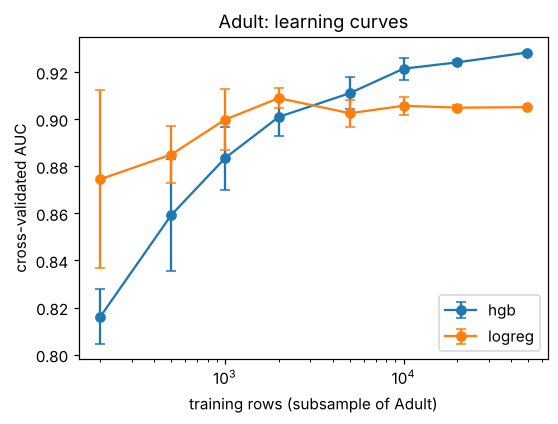

,model,n,mean,std
0,hgb,200,0.8161,0.0117
1,hgb,500,0.8593,0.0238
2,hgb,1000,0.8835,0.0134
3,hgb,2000,0.9010,0.0079
4,hgb,5000,0.9110,0.0069
5,hgb,10000,0.9214,0.0046
6,hgb,20000,0.9241,0.0009
7,hgb,48842,0.9283,0.0004
8,logreg,200,0.8745,0.0378
9,logreg,500,0.8850,0.0120


In [10]:
cache = os.path.join(RESULTS_DIR, "adult_learning_curve.csv")
if os.path.exists(cache):
    lc = pd.read_csv(cache)
else:
    adult = from_dataframe(adult_df, "adult")
    rows = []
    for size in [200, 500, 1000, 2000, 5000, 10000, 20000, adult.n]:
        for rep in range(3):
            d = subsample(adult, size, np.random.default_rng(rep))
            for key in ("logreg", "hgb"):
                rows.append({"n": d.n, "model": key, "rep": rep, "auc": cv_auc(key, d.X, d.y, seed=rep)})
    lc = pd.DataFrame(rows)
    lc.to_csv(cache, index=False)
lcm = lc.groupby(["model", "n"]).auc.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for key, g in lcm.groupby("model"):
    ax.errorbar(g.n, g["mean"], yerr=g["std"], marker="o", capsize=3, label=key)
ax.set_xscale("log")
ax.set_xlabel("training rows (subsample of Adult)")
ax.set_ylabel("cross-validated AUC")
ax.legend()
ax.set_title("Adult: learning curves")
plt.savefig(os.path.join(FIG_DIR, "adult_learning_curve.png"), dpi=200, bbox_inches="tight")
plt.show()
lcm.round(4)

### 2.6 Where does the signal in the incentive experiment come from?

The probes reject H₀ on the incentive experiment even after village is removed. Notebook 00 showed that the share of people receiving an incentive differs strongly between villages, so assignment was random *within* villages but with village-specific probabilities. Any individual covariate that varies systematically between villages, such as the distance to the results centre, can then carry information about the target.

A **design-aware permutation test** checks this explanation: labels are permuted only *within* villages, which keeps each village's incentive rate fixed. If the detected signal is entirely due to village-varying assignment rates, it should disappear under this null. Two diagnostics complement it:

1. how well distance (alone) identifies a person's village;
2. ordinary and within-village permutation tests of the two strongest model-based probes and of distance correlation.

In [11]:
def permutation_within_strata(probe, data, strata, B=200, seed=0):
    """Permutation test that shuffles labels only within strata (e.g. villages)."""
    rng = np.random.default_rng(seed)
    st = probe.prepare(data)
    t_obs = probe.stat(st, data.y)
    groups = [np.flatnonzero(strata == s) for s in np.unique(strata)]
    exceed = 0
    for _ in range(B):
        yb = data.y.copy()
        for g in groups:
            yb[g] = data.y[rng.permutation(g)]
        exceed += probe.stat(st, yb) >= t_obs - 1e-12
    return float(t_obs), (1 + exceed) / (B + 1)

cache = os.path.join(RESULTS_DIR, "thornton_design_check.csv")
if os.path.exists(cache):
    design = pd.read_csv(cache)
else:
    th_v = load_processed("thornton_village")
    keep = th_v.villnum.notna()
    th_v = th_v[keep].reset_index(drop=True)
    data = from_dataframe(th_v.drop(columns="villnum"), "thornton_individual")
    strata = th_v.villnum.to_numpy()
    rows = []
    for pr in [DistanceCorrelationProbe(), ModelProbe("forest", "M3_Forest"), ModelProbe("hgb", "M4_HGB")]:
        r_all = run_probe(pr, data, B=200, seed=5)
        t, p_within = permutation_within_strata(pr, data, strata, B=200, seed=5)
        rows.append({"probe": pr.name, "statistic": t, "p_ordinary_permutation": r_all["p"],
                     "p_within_village_permutation": p_within})
    # how much village information does distance carry?
    from sklearn.model_selection import cross_val_score, KFold
    vill_codes = pd.factorize(strata)[0]
    acc = cross_val_score(KNeighborsClassifier(1), th_v[["distvct"]].to_numpy(), vill_codes,
                          cv=KFold(5, shuffle=True, random_state=0)).mean()
    rows.append({"probe": "distance -> village (1-NN accuracy)", "statistic": acc,
                 "p_ordinary_permutation": np.nan, "p_within_village_permutation": np.nan})
    rows.append({"probe": "majority-village baseline accuracy", "statistic": np.bincount(vill_codes).max() / len(vill_codes),
                 "p_ordinary_permutation": np.nan, "p_within_village_permutation": np.nan})
    design = pd.DataFrame(rows)
    design.to_csv(cache, index=False)
design.round(4)

,probe,statistic,p_ordinary_permutation,p_within_village_permutation
0,S3_dCor,0.0466,0.0249,0.3532
1,M3_Forest,0.5552,0.0050,0.0348
2,M4_HGB,0.5736,0.0050,0.0149
3,distance -> village (1-NN accuracy),0.4436,NaN,NaN
4,majority-village baseline accuracy,0.0442,NaN,NaN
